# 3. 신경망
- 퍼셉트론으로 복잡한 함수 표현 가능.
- 가중치 설정 작업은 여전히 사람이 수동. 2장까지는 AND, OR 게이트 진리표를 보면서 적절한 가중치 값 정함.
- 신경망 성질 : 가중치 파라미터의 적절한 값을 데이터로부터 자동으로 학습하는 능력

## 3.1 신경망
- 신경망은 아래 순서로 구성된다
    - 입력 - 은닉 - 출력
- 퍼세븥론과 구조상으로 특별히 달라보이지 않음.
### 3.1.2 퍼셉트론 복습
- 퍼셉트론은 두 입력신호에 각각의 가중치를 곱하고, 편항을 더한 값을 활성화 함수에 넣어 나온 출력 신호를 출력한다.
- 편향의 입력 신호는 항상 1.
### 3.1.3 활성화 함수의 등장
- 활성화 함수 : 입력 신호의 총 합을 출력 신호로 변환하는 함수
- 가중치가 곱해진 입력 신호의 총합을 계산, 해당 합을 활성화 함수에 입력해 결과를 내는 2단게로 처리. 가중치가 달린 입력 신호와 편향의 총합을 계산. 해당 계산 값을 활성화 함수에 넣어 출력하는 흐름
- 단순 퍼셉트론 : 단층 네트워크에서 계단 함수를 활성화 함수로 사용한 모델
- 다층 퍼셉트론 : 여러 층으로 구성, 시그모이드 함수 등 매끈한 활성화 함수를 사용하는 네트워크 신경망

## 3.2 활성화 함수
- 활성화 함수는 임계값을 경계로 출력 변화.
- 퍼셉트론은 활성화 함수로 게단 함수를 채용.
- 신경망은 활성화 함수로 시그모이드 함수를 활용, 변환된 신호를 다음 뉴런으로 전달.

### 3.2.2 계단 함수 구현
- 입력이 0을 넘으면 1 출력, 그 외에는 0 출력

In [40]:
def step_function(x):
    if x > 0:
        return 1
    else:
        return 0

def step_function(x):
    y = x > 0
    return y.astype(np.int)

In [41]:
import numpy as np
x = np.array([-1.0, 1.0, 2.0])
x

array([-1.,  1.,  2.])

In [42]:
y = x > 0
y

array([False,  True,  True])

- 넘파이 배열에 부등호 연산을 수행하면 배열의 원소 각각에 부등호 연산을 수행한 bool 배열 생성. x의 원소 각각이 0보다 크면 True, 0 이하면 False로 변환, 새로운 배열 y 생성.
- y 는 bool 배열. 0, 1은 int형을 출력하는 함수. bool -> int
- 넘파이 배열의 자료형을 변환할 때는 astype() 메서드 이용. 원하는 지료형을 신수로 지정.

### 3.2.3 계단 함수의 그래프

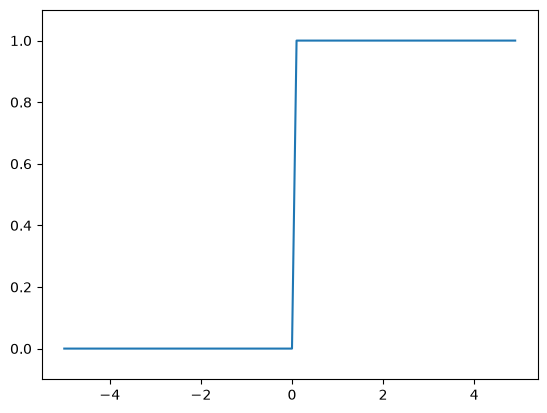

In [43]:
import numpy as np
import matplotlib.pyplot as plt

def step_function(x):
    return np.array(x > 0, dtype=int)

x = np.arange(-5.0, 5.0, 0.1)
y = step_function(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1)
plt.show()

### 3.2.4 시그모이드 함수 구현하기
- 브로드캐스트 : 넘파이 배열과 스칼라값의 연산이 넘파이 배열의 원소 각각과 스칼라값의 연산으로 바꿔 수행하는 것.

In [44]:
def sigmoid(x):
    return 1 / (1+np.exp(-x))

In [45]:
t = np.array([1.0, 2.0, 3.0])
1.0 + t

array([2., 3., 4.])

In [46]:
1.0 / t

array([1.        , 0.5       , 0.33333333])

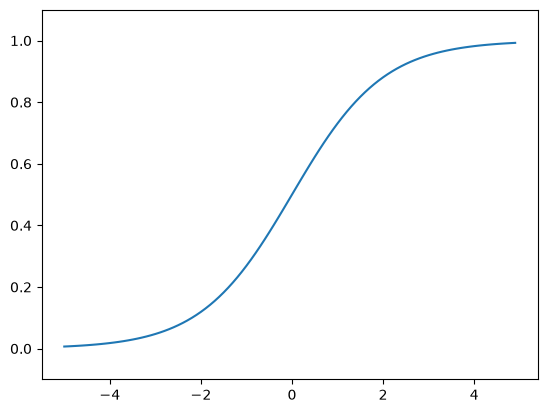

In [47]:
x = np.arange(-5.0, 5.0, 0.1)
y = sigmoid(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1)
plt.show()

### 3.2.5 시그모이드 함수와 계단 함수 비교
- 시그모이드 함수 : 부드러운 곡선, 입력에 따라 출력이 연속적으로 변화. 매끄로운 변화가 신경망 학습에 아주 중요한 역할
- 계단함수 : 0을 경계로 출력 변화.
- 계단 함수는 0, 1중 하나의 값만 돌려주고, 시그모이드 함수는 실수를 돌려줌. 퍼셉트론에서는 뉴런 사이에 0, 1이 흘림, 신겸망에서는 연속적인 실수가 흐름.
- 공통점 : 둘 다 ㅇ비력이 작을 때의 출력은 0에 가깝고, 입력이 커지면 출력이 1에 가까워지는 구조.
- 입력이 중요하면 큰 값 출력, 중요하지 않으면 작은 값 출력. 입력이 아무리 작거나 커도 출력은 0에서 1사이

### 3.2.6 비선형 함수
- 함수 : 어떤 값을 입력하면 그에 따른 값을 돌려주는 변환기.
- 선형 함수 : 입력시 출력이 입력의 상수배만큼 변하는 함수를 선형함수.
- 비선형 함수 : 문자 그대로 선형이 아닌 함수. 직선 1개로 그릴 수 없는 함수.
- 신경망에서는 선형 함수를 이용할 시 깊은 층이 의미 없어짐. 선형 함수는 층이 아무리 깊어도 같은 결과 출력. 활성화 함수로는 비선형 함수 사용.

### 3.2.7 ReLU 함수
- 입력이 0을 넘으면 입력 그대로 출력, 0 이하면 0 출력

In [48]:
def relu(x):
    return np.maximum(0, x)

## 3.3 다차원 배열의 계산
- 넘파이의 다차원 배열 사용 계산법 숙달 시 효율적인 신경망 구현.
### 3.3.1 다차원 배열
- 다차원 배열의 기본은 숫자의 집합. 숫자가 한 줄로 늘어섬, 직사각형으로 늘어섬, 3차원, N차원으로 나열하는것을 통틀어 다차원 배열.

In [49]:
import numpy as np
A = np.array([1,2,3,4])
print(A)

[1 2 3 4]


In [50]:
np.ndim(A)

1

In [51]:
A.shape

(4,)

In [52]:
A.shape[0]

4

- 배열의 차원수는 np.ndim() 함수로 확인. 배열의 현상은 인스턴스 변수인 shape로 확인.
- A.shape이 튜플 반환에 유의. 1차원 배열이어도 다차원 배열일 때와 통일된 형태로 결과 반환을 위해 튜플로 반환.

In [53]:
B = np.array([[1,2],[3,4],[5,6]])
print(B)

[[1 2]
 [3 4]
 [5 6]]


In [54]:
np.ndim(B)

2

In [55]:
B.shape

(3, 2)

- 2차원 배열은 행렬이라 이름. 가로 방향을 행, 세로 방향을 열.
### 3.3.2 행렬 곱
- 행렬 곱은 왼쪽 행렬 행과 오른쪽 행렬 열을 원소별로 곱해 연산.
- 계산 결과가 새로운 다차원 배열의 원소

In [56]:
A = np.array([[1,2],[3,4]])
A.shape

(2, 2)

In [57]:
B = np.array([[5,6],[7,8]])
B.shape

(2, 2)

In [58]:
np.dot(A, B)

array([[19, 22],
       [43, 50]])

- np.dot() : 입력이 1차원 배열이면 벡터, 2차원 배열이면 행렬 곱 계산. 행렬은 곱하는 순서에 따라 결과가 다르기 때문에 (A, B)와 (B, A)의 결과값은 다른다.

In [59]:
A = np.array([[1,2,3],[4,5,6]])
A.shape

(2, 3)

In [60]:
B = np.array([[1,2],[3,4],[5,6]])
B.shape

(3, 2)

In [61]:
np.dot(A, B)

array([[22, 28],
       [49, 64]])

In [62]:
C = np.array([[1,2],[3,4]])
C.shape

(2, 2)

In [63]:
A.shape

(2, 3)

In [65]:
np.dot(A, C)

ValueError: shapes (2,3) and (2,2) not aligned: 3 (dim 1) != 2 (dim 0)

- 행렬 A의 1번째 차원과 행렬 C의 0번째 차원 원소수가 달라 연산 불가.
- 다차원 배열 연산 시 두 행렬의 대응 차원의 원소 수 일치.

In [ ]:
A = np.array([[1,2], [3,4], [5,6]])
A.shape

(3, 2)

In [ ]:
B = np.array([7,8])
B.shape

(2,)

In [ ]:
np.dot(A, B)

array([23, 53, 83])

### 3.3.3 신경망에서의 행렬 곱
- 행렬을 활용한 신경망 구현. 간단한 신경망 가정. 해당 신경망은 편향, 활성화 함수 생략 및 가중치
- 행렬 곱으로 한꺼번에 연산하는 기능은 신경망 구현시 매우 중요

In [ ]:
X = np.array([1,2])
X.shape

(2,)

In [ ]:
W = np.array([[1,3,5],[2,4,6]])
print(W)

[[1 3 5]
 [2 4 6]]


In [ ]:
W.shape

(2, 3)

In [ ]:
Y = np.dot(X, W)
print(Y)

[ 5 11 17]


## 3.4 3층 신경망 구하기
- 가중치 문자 표현시 총 3곳에 숫자를 표기한다.
- 오른쪽 위 : 1층 가중치
- 오른쪽 아래 1번 : 다음 층의 1번째 뉴런
- 오른쪽 아래 2번 : 앞 층의 2번째 뉴런

In [ ]:
X = np.array([1.0, 0.5])
W1 = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
B1 = np.array([0.1, 0.2, 0.3])

print(W1.shape)
print(X.shape)
print(B1.shape)

A1 = np.dot(X, W1) + B1
print(A1)

(2, 3)
(2,)
(3,)
[0.3 0.7 1.1]


In [ ]:
Z1 = sigmoid(A1)

print(A1)
print(Z1)

[0.3 0.7 1.1]
[0.57444252 0.66818777 0.75026011]


In [ ]:
W2 = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
B2 = np.array([0.1, 0.2])

print(Z1.shape)
print(W2.shape)
print(B2.shape)

A2 = np.dot(Z1, W2) + B2
Z2 = sigmoid(A2)

(3,)
(3, 2)
(2,)


In [ ]:
def identify_function(x):
    return x
# 항등함수. 입력 그대로 출력하는 함수.

W3 = np.array([[0.1, 0.3], [0.2, 0.4]])
B3 = np.array([0.1, 0.2])

A3 = np.dot(Z2, W3) + B3
Y = identify_function(A3)

In [ ]:
def init_network():
    network = {}
    network['W1'] = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
    network['b1'] = np.array([0.1, 0.2, 0.3])
    network['W2'] = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
    network['b2'] = np.array([0.1, 0.2])
    network['W3'] = np.array([[0.1, 0.3], [0.2, 0.4]])
    network['b3'] = np.array([0.1, 0.2])
    
    return network

def forward(network, x):
    W1, W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']
    
    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)
    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)
    a3 = np.dot(z2, W3) + b3
    y = identify_function(a3)
    
    return y

network = init_network()
x = np.array([1.0, 0.5])
y = forward(network, x)
print(y)

[0.31682708 0.69627909]


#### 함수 정의
- init_network : 가중치와 편향 초기화, 딕셔너리 변수인 network에 저장. 딕셔너리 변수 network에 각 층에 필요한 파라미터 저장.
- forward : 입력 신호를 출력으로 변환하는 처리 과정 모두 구현. 신호가 순방향으로 전달됨을 알리기 위함.

## 3.5 출력층 설계하기
- 신경망은 분류, 회귀 모두 이용.
- 문제에 따라 출력층에서 사용하는 활성화 함수 달라짐.
- 회귀 문제 : 항등 함수, 분류 문제 : 소프트맥스 함수 사용
- 분류 : 데이터가 어느 클래스에 속하는가?
- 회귀 : 입력 데이터에서 연속적 수치 예측
### 3.5.1 항등함수, 소프트맥스 함수 구현
- 항등함수 : 입력 그대로 출력. 입력 = 출력. 출력측엥서 항등함수 사용시 입력신호 그대로 출력 신호. 
- 소프트 맥스 함수 : 소프트맥스의 출력은 모든 입력신호로부터 화살표 받음. 출력층의 각 뉴런이 모든 입력 신호에 영향.

In [ ]:
a = np.array([0.3, 2.9, 4.0])

exp_a = np.exp(a)
print(exp_a)

[ 1.34985881 18.17414537 54.59815003]


In [ ]:
sum_exp_a = np.sum(exp_a)
print(sum_exp_a)

74.1221542101633


In [ ]:
y = exp_a / sum_exp_a
print(y)

[0.01821127 0.24519181 0.73659691]


In [ ]:
def softmax(a):
    exp_a = np.exp(a)
    sum_exp_a = np.sum(exp_a)
    y = exp_a / sum_exp_a

    return y

### 3.5.2 소프트맥스 함수 구현 시 주의점
- 컴퓨터로 계산 시 결함 발생.
- overflow : 소프트맥스 함수는 지수 함수를 사용. e^x 함수는 x가 커질수록 inf 값 반환. 해당 값 나눗셉시 결과 수치 불안정.
- 해결 방안 : 입력 신호 중 최댓값을 빼 올바르게 계산.

In [ ]:
a = np.array([1010, 1000, 990])
np.exp(a) / np.sum(np.exp(a))

C:\Users\user\AppData\Local\Temp\ipykernel_12156\832863605.py:2: RuntimeWarning: overflow encountered in exp
  np.exp(a) / np.sum(np.exp(a))
C:\Users\user\AppData\Local\Temp\ipykernel_12156\832863605.py:2: RuntimeWarning: invalid value encountered in divide
  np.exp(a) / np.sum(np.exp(a))


array([nan, nan, nan])

In [ ]:
c = np.max(a)
a - c

array([  0, -10, -20])

In [ ]:
np.exp(a-c) / np.sum(np.exp(a-c))

array([9.99954600e-01, 4.53978686e-05, 2.06106005e-09])

In [ ]:
def softmax(a):
    c = np.max(a)
    exp_a = np.exp(a - c) # 오버플로 대책
    sum_exp_a = np.sum(exp_a)
    y = exp_a / sum_exp_a
    
    return y

### 3.5.3 소프트맥스 함수 특징
- 출력값은 0에서 1.0 사이의 실수. 출력의 총 합은 1.
- 출력값의 총 합이 1임을 이용해 소프트맥스 함수의 출력을 확률로 해석.
- 소프트맥스 함수를 적용해도 각 원소의 대소 관계 변화 없음. 그 이유는 지수함수 exp(x)가 단조 증가함수 이기 때문.
- 기계학습 문제 풀이는 학습과 추론 단계를 거춰 해석. 모델 학습 -> 데이터 추론 순서

In [ ]:
a = np.array([0.3, 2.9, 4.0])
y = softmax(a)
print(y)

[0.01821127 0.24519181 0.73659691]


In [ ]:
np.sum(y)

np.float64(1.0)

## 3.6 손글씨 숫자 인식
- 이미 학습된 파라미터 활용해 학습 과정 생략 및 추론 과정 구현
- 추론 과정 : 신경망의 순전파.

In [ ]:
import sys, os
sys.path.append(os.pardir)
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = load_mnist(flatten=True, normalize=False)

print(x_train.shape)
print(t_train.shape)
print(x_test.shape)
print(t_test.shape)

(60000, 784)
(60000,)
(10000, 784)
(10000,)


- one-hot encoding : one_hot_label 레이블로 형태 저장. 배열에 정답 원소만 1이고, 나머지는 0.
- False 면 숫자 형태의 레이블 저장, True일 때는 레이블을 원-핫 인코딩해 저장.
- pickle : 프로그램 실행 중 특정 객체를 파일로 저장하는 기능. 저장한 pickle 파일 로드 시 실행 당시 객체 즉시 복원.

In [ ]:
import sys, os
sys.path.append(os.pardir)
import numpy as np
from dataset.mnist import load_mnist
from PIL import Image

def img_swhow(img):
    pil_img = Image.fromarray(np.uint8(img))
    pil_img.show()

(x_train, t_train), (x_test, t_test) = load_mnist(flatten=True, normalize=False)

img = x_train[0]
label = t_train[0]
print(label)

print(img.shape)
img = img.reshape(28, 28)
print(img.shape)

5
(784,)
(28, 28)


### 3.6.2 신경망의 추론 처리
- 데이터셋을 갖고 추론 수행하는 신경망 구현.
- 3층 신경망은 은닉층이 2개, 첫 번째 은닉층에 50개 뉴런, 두 번째 은닉층에 100개 뉴런 배치.
- 순서대로 작업 처리할 함수 get_data(), init_network(), predict() 정의
    - init_network() : 피클 파일인 pkl에 저장된 학습된 가중치 매개변수 읽음. 가중치, 편향 매개변수가 딕셔너리 변수로 저장.
- 정규화 : 데이터를 특정 범위로 변환하는 처리
- 전처리 : 신경망의 입력 데이터에 특정 변환을 가하는 것

In [ ]:
def get_data():
    (x_train, t_train), (x_test, t_test) = load_mnist(flatten=True, normalize=True, one_hot_label=False)
    return x_test, t_test

In [ ]:
def init_network():
    with open("dataset/sample_weight.pkl", 'rb') as f:
        network = pickle.load(f)
    return network

In [ ]:
def predict(network, x):
    W1, W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']

    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)
    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)
    a3 = np.dot(z2, W3) + b3
    y = softmax(a3)

    return y

In [67]:
import sys, os, pickle
sys.path.append(os.pardir)
import numpy as np
from dataset.mnist import load_mnist
from PIL import Image

x, t = get_data()
network = init_network()

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

accuracy_cnt = 0
for i in range(len(x)):
    y = predict(network, x[i])
    p = np.argmax(y) # 확률이 가장 높은 원소의 인덱스를 얻는다
    if p == t[i]:
        accuracy_cnt += 1

print("Accuracy:" + str(float(accuracy_cnt) / len(x)))

Accuracy:0.9352


In [68]:
x, _ = get_data()
network = init_network()
W1, W2, W3 = network['W1'], network['W2'], network['W3']

x.shape

(10000, 784)

- 배치 : 하나로 묶은 입력 데이터. 
- 배치 처리는 컴퓨터 연산 많은 이점. 이미지 1장당 처리 시간 감소.
    - 수치 계산 라이브러리 대부분이 큰 배열을 효율적으로 처리할 수 있도록 최적화
    - 커다란 신경망에서 데이터 전송이 병목 작용 경우 발생, 배치 처리로 버스 부하 감소.
- 배치 처리를 수행하여 배열로 이뤄진 계산 진행, 큰 배열을 한꺼번에 계산하는 것이 분할 된 작을 배열 여러번 계상보다 빠름

In [69]:
x, t = get_data()
network = init_network()

batch_size = 100 # 배치 크기
accuracy_cnt = 0

for i in range(0, len(x), batch_size):
    x_batch = x[i:i+batch_size]
    y_batch = predict(network, x_batch)
    p = np.argmax(y_batch, axis=1)
    accuracy_cnt += np.sum(p == t[i:i+batch_size])

print("Accuracy:" + str(float(accuracy_cnt) / len(x)))

Accuracy:0.9352


In [70]:
list(range(0, 10))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [71]:
list(range(0, 10, 3))

[0, 3, 6, 9]

In [72]:
x = np.array([[0.1, 0.8, 0.1], [0.3, 0.1, 0.6], [0.2, 0.5, 0.3], [0.8, 0.1, 0.1]])
y = np.argmax(x, axis=1)
print(y)

[1 2 1 0]


In [73]:
y = np.array([1, 2, 1, 0])
t = np.array([1, 2, 0, 0])
print(y == t)

[ True  True False  True]


In [74]:
np.sum(y == t)

np.int64(3)